# Day 2: Clinical baseline (age + stage)

**Goal:** build the benchmark that every gene-based model must beat.

1. Load the cleaned survival table from Day 1 and add age and pathologic stage
2. Kaplan-Meier curves by stage, with a log-rank test
3. Cox proportional hazards model: age + stage
4. Check the proportional hazards assumption
5. Cross-validated C-index (this is the baseline number)

**Needs:** `data/processed/y_survival.pkl` (from Day 1) and `data/data_clinical_patient.txt`

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.plotting import add_at_risk_counts
from lifelines.statistics import multivariate_logrank_test, proportional_hazard_test
from sklearn.model_selection import RepeatedStratifiedKFold

DATA = Path("../data")
FIGS = Path("../results/figures")
RES = Path("../results")
FIGS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load survival (Day 1) and clinical data

In [2]:
y = pd.read_pickle(DATA / "processed" / "y_survival.pkl")
clin = pd.read_csv(DATA / "data_clinical_patient.txt", sep="\t", comment="#").set_index("PATIENT_ID")

df = y.join(clin[["AGE", "PATH_STAGE"]], how="left")
df["time"] = df["OS.time"] / 365.25      # years
df = df.rename(columns={"OS": "event"})

print("patients:", len(df))
print("\nAGE:"); print(df["AGE"].describe())
print("\nPATH_STAGE values:"); print(df["PATH_STAGE"].value_counts(dropna=False))

patients: 1068

AGE:
count    1054.000000
mean       58.222011
std        12.906636
min        26.000000
25%        49.000000
50%        58.000000
75%        67.000000
max        89.000000
Name: AGE, dtype: float64

PATH_STAGE values:
PATH_STAGE
Stage IIA     347
Stage IIB     250
Stage IIIA    152
Stage I        90
Stage IA       85
Stage IIIC     62
Stage IIIB     25
Stage IV       20
Stage X        12
NaN            11
Stage IB        6
Stage II        6
Stage III       2
Name: count, dtype: int64


## 2. Build clean clinical variables

- `AGE` is numeric (I express it per 10 years so the hazard ratio is easy to read)
- `PATH_STAGE` has sub-stages (IA, IB, IIA, ...). I collapse them to I, II, III, IV. Stage X / missing becomes NaN.

In [3]:
df["AGE"] = pd.to_numeric(df["AGE"], errors="coerce")

# take the roman numeral before any letter suffix (IA -> I, IIB -> II); Stage X / missing -> NaN
stage = df["PATH_STAGE"].astype(str).str.extract(r"Stage\s+(IV|III|II|I)", expand=False)
df["stage"] = stage

log = {"patients": len(df)}
df = df.dropna(subset=["AGE", "stage"])
log["with age and stage"] = len(df)
print(pd.Series(log, name="count"))
print()
print(df["stage"].value_counts().reindex(["I", "II", "III", "IV"]))
print("\nDeaths per stage:"); print(df.groupby("stage")["event"].agg(["sum", "count"]).reindex(["I", "II", "III", "IV"]))

patients              1068
with age and stage    1031
Name: count, dtype: int64

stage
I      180
II     592
III    239
IV      20
Name: count, dtype: int64

Deaths per stage:
       sum  count
stage            
I       16    180
II      65    592
III     43    239
IV      15     20


## 3. Kaplan-Meier curves by stage

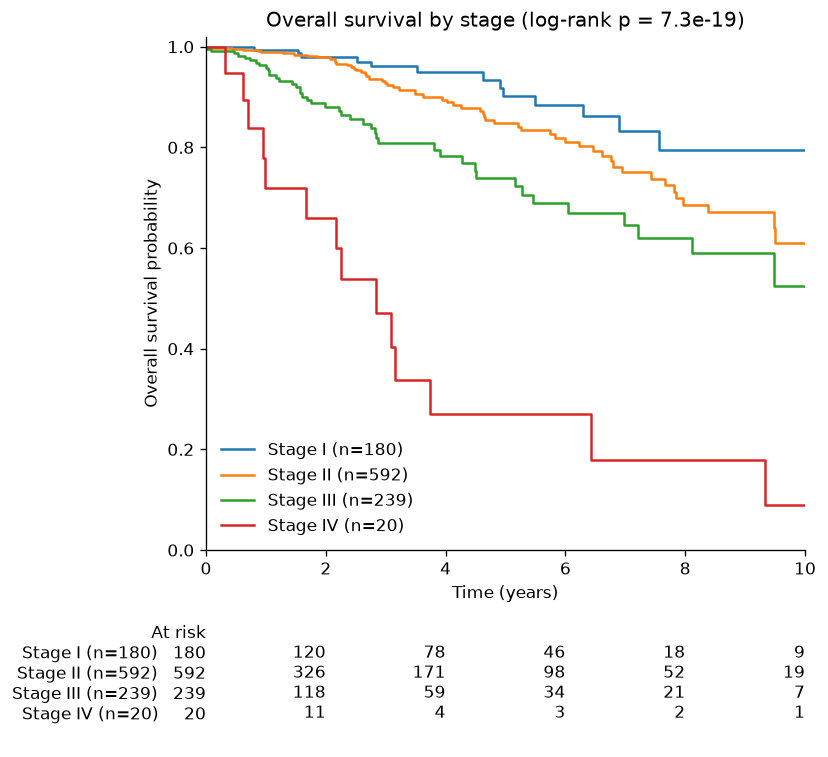

log-rank p-value: 7.288276491475391e-19


In [10]:
order = ["I", "II", "III", "IV"]
fig, ax = plt.subplots(figsize=(7, 6.5))
kmfs = []
for s in order:
    sub = df[df["stage"] == s]
    k = KaplanMeierFitter().fit(sub["time"], sub["event"], label=f"Stage {s} (n={len(sub)})")
    k.plot_survival_function(ax=ax, ci_show=False)
    kmfs.append(k)

lr = multivariate_logrank_test(df["time"], df["stage"], df["event"])
ax.set_xlim(0, 10); ax.set_ylim(0, 1.02)          # few patients remain beyond 10 years
ax.set_title(f"Overall survival by stage (log-rank p = {lr.p_value:.2g})")
ax.set_xlabel("Time (years)"); ax.set_ylabel("Overall survival probability")
ax.legend(loc="lower left", frameon=False)
add_at_risk_counts(*kmfs, ax=ax, rows_to_show=["At risk"])
plt.tight_layout()
plt.savefig(FIGS / "km_by_stage.png", dpi=200, bbox_inches="tight")
plt.show()
print("log-rank p-value:", lr.p_value)

## 4. Cox proportional hazards model: age + stage
Stage I is the reference group.

In [5]:
model_df = pd.DataFrame({
    "time": df["time"],
    "event": df["event"],
    "age_per10y": df["AGE"] / 10,
})
stage_dummies = pd.get_dummies(df["stage"], prefix="stage", drop_first=False).astype(float)
stage_dummies = stage_dummies.drop(columns="stage_I")        # reference = stage I
model_df = pd.concat([model_df, stage_dummies], axis=1)

cph = CoxPHFitter()
cph.fit(model_df, duration_col="time", event_col="event")
cph.print_summary(decimals=2, columns=["coef", "exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"])

<lifelines.CoxPHFitter: fitted with 1031 total observations, 892 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 1031
number of events observed = 139
   partial log-likelihood = -755.50
         time fit was run = 2026-11-02 22:35:57 UTC

---
            coef exp(coef) exp(coef) lower 95% exp(coef) upper 95%      p
covariate                                                                
age_per10y  0.36      1.43                1.24                1.64 <0.005
stage_II    0.55      1.74                1.00                3.01   0.05
stage_III   1.21      3.35                1.88                5.98 <0.005
stage_IV    2.42     11.26                5.55               22.85 <0.005
---
Concordance = 0.75
Partial AIC = 1519.00
log-likelihood ratio test = 74.36 on 4 df
-log2(p) of ll-ratio test = 48.39

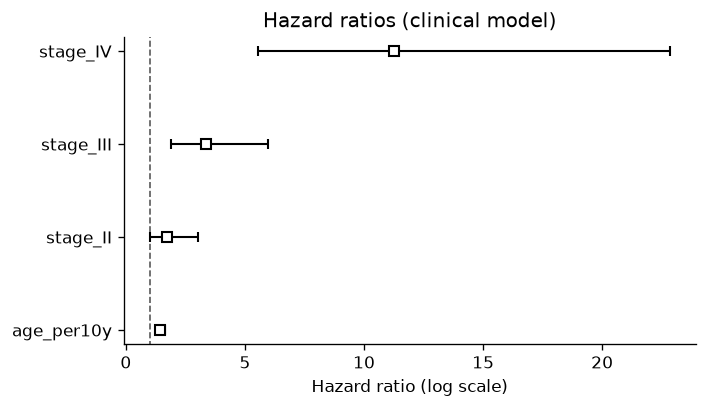

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
cph.plot(hazard_ratios=True, ax=ax)
ax.set_title("Hazard ratios (clinical model)")
ax.set_xlabel("Hazard ratio (log scale)")
plt.tight_layout()
plt.savefig(FIGS / "clinical_hazard_ratios.png", dpi=200, bbox_inches="tight")
plt.show()

**How to read it:** `exp(coef)` is the hazard ratio. For example, `age_per10y = 1.5` would mean each additional 10 years of age multiplies the death hazard by 1.5. `stage_III = 3.0` would mean stage III patients have 3x the hazard of stage I patients (at the same age).
Wide confidence intervals (especially stage IV) mean few patients or events.

## 5. Check the proportional hazards assumption
Cox models assume each variable's effect is constant over time. A small p-value (< 0.05) suggests a violation.

In [7]:
ph = proportional_hazard_test(cph, model_df, time_transform="rank")
ph.print_summary(decimals=3)

## 6. Baseline C-index
The **C-index** is the probability that, for a random comparable pair of patients, the model gives the higher risk to the patient who dies first. 0.5 = random guessing, 1.0 = perfect.

I report (a) the apparent C-index on the training data (optimistic) and (b) a 5-fold cross-validation repeated 10 times (honest estimate).

In [9]:
PEN = 0.01   # tiny ridge penalty: prevents divergence when a stage has very few patients

# 1. Apparent C-index with the same penalized model used for CV
cph_pen = CoxPHFitter(penalizer=PEN).fit(model_df, duration_col="time", event_col="event")
print(f"Apparent C-index (train): {cph_pen.concordance_index_:.3f}")

# 2. Stratify folds by stage AND event, so every fold has some stage IV patients and deaths
strat = df.loc[model_df.index, "stage"].astype(str) + "_" + model_df["event"].astype(str)
print("smallest group size:", strat.value_counts().min())

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scores = []
for train_idx, test_idx in rskf.split(model_df, strat):
    tr, te = model_df.iloc[train_idx], model_df.iloc[test_idx]
    m = CoxPHFitter(penalizer=PEN).fit(tr, duration_col="time", event_col="event")
    scores.append(m.score(te, scoring_method="concordance_index"))

scores = np.array(scores)
print(f"Cross-validated C-index: {scores.mean():.3f} +/- {scores.std():.3f}  ({len(scores)} folds)")

RES.mkdir(exist_ok=True)
with open(RES / "clinical_baseline.json", "w") as f:
    json.dump({"model": "Cox age + stage (ridge 0.01)", "n_patients": int(len(model_df)),
               "n_events": int(model_df["event"].sum()),
               "cindex_cv_mean": float(scores.mean()), "cindex_cv_sd": float(scores.std())}, f, indent=2)
df.to_pickle(DATA / "processed" / "clinical.pkl")

Apparent C-index (train): 0.749
smallest group size: 5
Cross-validated C-index: 0.739 +/- 0.046  (50 folds)


### Summary
- The clinical-only C-index above is the **bar to beat** in Day 4-5.
- If gene models only match it, say so honestly in the README.
- Next (Day 3): filter the ~39,000 genes down to a manageable set **inside the cross-validation folds**.